# 04 · Detección de outliers multivariados por votación
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** `03_train`, `03_test` · **Salida:** `04_train` (menos filas), `04_test` (mismas
filas + score), `artifacts/detectores.joblib`, `reports/outliers.json`.

### Por qué multivariado y no univariado

Un cliente puede tener un ingreso **normal** y un préstamo **normal**... pero un préstamo enorme
**para su ingreso**. Cada variable por separado no lo detecta; la **combinación** sí. Los outliers
que importan en riesgo casi siempre son **multivariados**.

### La estrategia: no confiar en un solo método

Cada detector tiene un sesgo distinto (supuestos de distribución, de densidad, de aislamiento).
Usamos **tres** y los hacemos **votar**:

| Método | En qué se basa | Debilidad |
|---|---|---|
| **Mahalanobis** | Distancia al centro, corregida por covarianza | Asume ~normalidad; se "enmascara" con outliers |
| **Isolation Forest** | Qué tan fácil es *aislar* un punto con cortes aleatorios | Menos interpretable |
| **LOF** | Densidad local relativa a los vecinos | Sensible a `k` |

**Decisión por votación:** un cliente es outlier si **≥ 2 de los 3** lo marcan (consenso). Así
ningún método manda solo, y los falsos positivos idiosincráticos de uno se filtran.

> 🔒 Todo se ajusta sobre TRAIN. **El test NUNCA pierde filas** — en producción los clientes
> llegan de a uno y no se descartan; solo se les anota el score para revisión. Los outliers se
> eliminan **solo de TRAIN**, para que el modelo aprenda del patrón central, no de las anomalías.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pipeline_io import (
    TARGET, SEGMENT_COL, SEED, load_stage, save_stage, save_artifact, save_report, save_table,
    set_plot_theme, COLOR_OK, COLOR_BAD, COLOR_NEUTRAL, COLOR_WARN,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

set_plot_theme()

train = load_stage("03_train")
test = load_stage("03_test")

y_train = train[TARGET]
seg_train = train[SEGMENT_COL]
X_train = train.drop(columns=[TARGET, SEGMENT_COL])
X_test = test.drop(columns=[TARGET, SEGMENT_COL])

# Contaminación esperada: fracción de outliers que anticipamos. Es un HIPERPARÁMETRO de negocio,
# no un dato. Lo fijamos y lo usamos de forma consistente en los tres métodos.
CONTAMINACION = 0.05

print("TRAIN:", X_train.shape, "| TEST:", X_test.shape)
print(f"Contaminación esperada: {CONTAMINACION:.0%}")

TRAIN: (491, 11) | TEST: (123, 11)
Contaminación esperada: 5%


## 4.1 Espacio de detección

Los tres métodos usan **distancias**, así que necesitan datos numéricos, sin nulos y en escala
común. Hacemos un preprocesamiento **local y mínimo** (solo para detectar): imputación mediana +
`log1p` sobre las sesgadas + estandarización. Todo **ajustado en TRAIN**.

> Esto NO es el pipeline oficial (ese es el NB06). Es un preprocesamiento desechable cuyo único
> fin es medir distancias de forma sensata. Por eso se queda dentro de este notebook.

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

cols_num = X_train.select_dtypes("number").columns.tolist()
sesgadas = [c for c in cols_num if X_train[c].skew() > 1]
print("Numéricas:", cols_num)
print("Se log-transforman (skew>1):", sesgadas)

imputer = SimpleImputer(strategy="median").fit(X_train[cols_num])

def preparar(df):
    Z = pd.DataFrame(imputer.transform(df[cols_num]), columns=cols_num, index=df.index)
    for c in sesgadas:
        Z[c] = np.log1p(Z[c].clip(lower=0))
    return Z

Ztr_raw = preparar(X_train)
Zte_raw = preparar(X_test)

scaler = StandardScaler().fit(Ztr_raw)
Ztr = pd.DataFrame(scaler.transform(Ztr_raw), columns=cols_num, index=X_train.index)
Zte = pd.DataFrame(scaler.transform(Zte_raw), columns=cols_num, index=X_test.index)

print("Espacio de detección listo:", Ztr.shape)

Numéricas: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Se log-transforman (skew>1): ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
Espacio de detección listo: (491, 5)


## 4.2 Método 1 — Distancia de Mahalanobis

La distancia de Mahalanobis mide qué tan lejos está un punto del centro de la nube,
**corrigiendo por la covarianza** (a diferencia de la euclidiana, tiene en cuenta que las
variables están correlacionadas):

$$D_M(x) = \sqrt{(x - \mu)^\top \Sigma^{-1} (x - \mu)}$$

Bajo normalidad multivariada, $D_M^2$ sigue una **χ²** con *p* grados de libertad (p = nº de
variables). Eso nos da un **corte objetivo**: marcamos como outlier los puntos por encima del
cuantil χ².

In [3]:
from scipy.stats import chi2
from sklearn.covariance import EmpiricalCovariance, MinCovDet

p = Ztr.shape[1]
corte_chi2 = chi2.ppf(1 - CONTAMINACION, df=p)
print(f"Grados de libertad (nº variables): {p}")
print(f"Corte χ² al {1-CONTAMINACION:.0%}: D² > {corte_chi2:.2f} → outlier")

# Mahalanobis CLÁSICO (media y covarianza empíricas, ajustadas en TRAIN)
cov_clasica = EmpiricalCovariance().fit(Ztr)
d2_tr_clasico = cov_clasica.mahalanobis(Ztr)
d2_te_clasico = cov_clasica.mahalanobis(Zte)

# Mahalanobis ROBUSTO (MCD: covarianza mínima determinante, resistente a outliers)
cov_robusta = MinCovDet(random_state=SEED).fit(Ztr)
d2_tr_robusto = cov_robusta.mahalanobis(Ztr)
d2_te_robusto = cov_robusta.mahalanobis(Zte)

flag_maha_clasico = d2_tr_clasico > corte_chi2
flag_maha = d2_tr_robusto > corte_chi2   # usamos el ROBUSTO como oficial

print(f"\nMarcados por Mahalanobis clásico: {flag_maha_clasico.sum()}")
print(f"Marcados por Mahalanobis robusto: {flag_maha.sum()}")

Grados de libertad (nº variables): 5
Corte χ² al 95%: D² > 11.07 → outlier

Marcados por Mahalanobis clásico: 40
Marcados por Mahalanobis robusto: 117


### Clásico vs robusto: el efecto de enmascaramiento

El Mahalanobis clásico usa una covarianza que **los propios outliers inflan** — se "enmascaran"
a sí mismos y acaban pareciendo menos extremos. El robusto (MCD) estima la covarianza con el
subconjunto más compacto de los datos, así que **ve los outliers que el clásico esconde**.

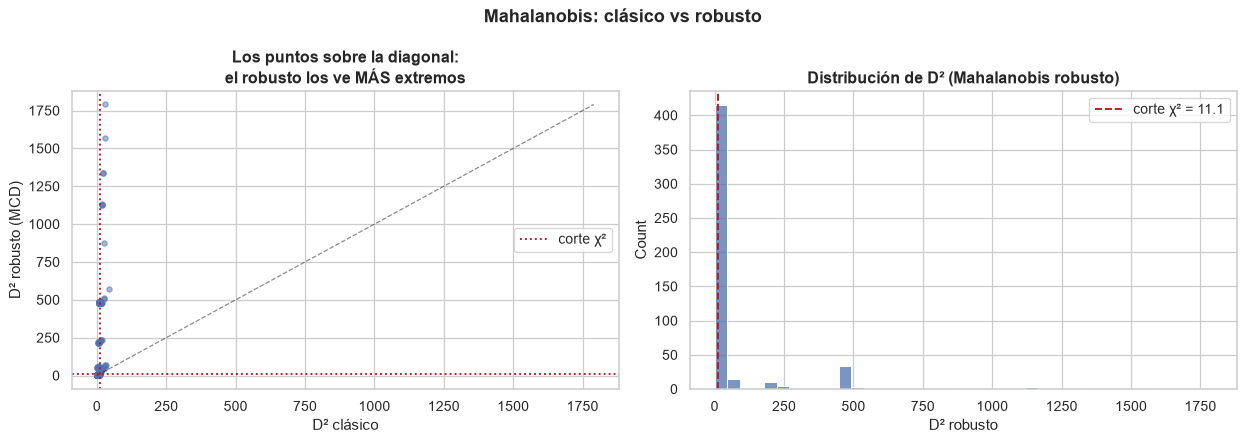

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lim = max(d2_tr_clasico.max(), d2_tr_robusto.max())
axes[0].scatter(d2_tr_clasico, d2_tr_robusto, s=18, alpha=0.5, color=COLOR_NEUTRAL)
axes[0].plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
axes[0].axhline(corte_chi2, color=COLOR_WARN, ls=":", label="corte χ²")
axes[0].axvline(corte_chi2, color=COLOR_WARN, ls=":")
axes[0].set_xlabel("D² clásico"); axes[0].set_ylabel("D² robusto (MCD)")
axes[0].set_title("Los puntos sobre la diagonal:\nel robusto los ve MÁS extremos"); axes[0].legend()

sns.histplot(d2_tr_robusto, bins=40, ax=axes[1], color=COLOR_NEUTRAL)
axes[1].axvline(corte_chi2, color=COLOR_WARN, ls="--", label=f"corte χ² = {corte_chi2:.1f}")
axes[1].set_xlabel("D² robusto"); axes[1].set_title("Distribución de D² (Mahalanobis robusto)")
axes[1].legend()
plt.suptitle("Mahalanobis: clásico vs robusto", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4.3 Método 2 — Isolation Forest

Aísla puntos con cortes aleatorios: un outlier se separa del resto con **pocos cortes** (queda
solo enseguida). No asume ninguna distribución. Se ajusta en TRAIN y se aplica a ambos.

In [5]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=CONTAMINACION, random_state=SEED, n_estimators=200).fit(Ztr)
flag_iso = iso.predict(Ztr) == -1          # -1 = outlier
score_iso_tr = -iso.score_samples(Ztr)      # mayor = más anómalo
score_iso_te = -iso.score_samples(Zte)
print(f"Marcados por Isolation Forest: {flag_iso.sum()}")

Marcados por Isolation Forest: 25


## 4.4 Método 3 — Local Outlier Factor (LOF)

Compara la **densidad local** de un punto con la de sus vecinos. Un punto en una zona mucho menos
densa que su vecindario es un outlier. Usamos `novelty=True` para poder **ajustar en TRAIN y
aplicar a TEST** (fit en train, predict en test).

In [6]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINACION, novelty=True).fit(Ztr)
flag_lof = lof.predict(Ztr) == -1
score_lof_tr = -lof.score_samples(Ztr)
score_lof_te = -lof.score_samples(Zte)
print(f"Marcados por LOF: {flag_lof.sum()}")

Marcados por LOF: 21


## 4.5 La votación

Juntamos los tres votos en una matriz y contamos. **Consenso = ≥ 2 de 3.**

In [7]:
votos = pd.DataFrame({
    "Mahalanobis": flag_maha.astype(int),
    "IsolationForest": flag_iso.astype(int),
    "LOF": flag_lof.astype(int),
}, index=X_train.index)
votos["n_votos"] = votos.sum(axis=1)
votos["consenso"] = votos["n_votos"] >= 2

print("Distribución de votos (nº de métodos que marcan a cada cliente):")
print(votos["n_votos"].value_counts().sort_index().to_frame("n_clientes").to_string())
print()
print(f"Marcados por CADA método:")
for m in ["Mahalanobis", "IsolationForest", "LOF"]:
    print(f"  {m:16s}: {int(votos[m].sum())}")
print(f"\nCONSENSO (≥2 de 3): {int(votos['consenso'].sum())} clientes")

Distribución de votos (nº de métodos que marcan a cada cliente):
         n_clientes
n_votos            
0               374
1                73
2                42
3                 2

Marcados por CADA método:
  Mahalanobis     : 117
  IsolationForest : 25
  LOF             : 21

CONSENSO (≥2 de 3): 44 clientes


### ¿En qué coinciden los métodos?

La matriz de acuerdo muestra cuántos clientes marca cada **par** de métodos en común. Si dos
métodos coincidieran siempre, sobraría uno; si nunca coincidieran, no habría consenso posible.

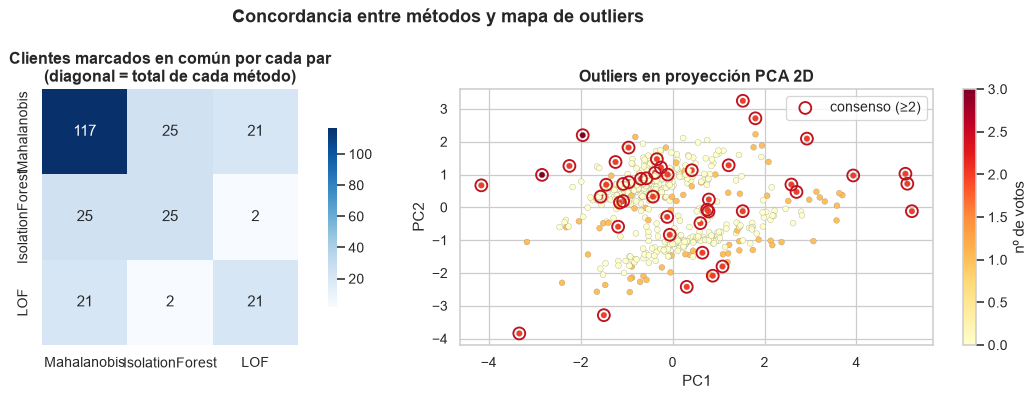

In [8]:
metodos = ["Mahalanobis", "IsolationForest", "LOF"]
acuerdo = pd.DataFrame(index=metodos, columns=metodos, dtype=int)
for a in metodos:
    for b in metodos:
        acuerdo.loc[a, b] = int(((votos[a] == 1) & (votos[b] == 1)).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(acuerdo.astype(int), annot=True, fmt="d", cmap="Blues", ax=axes[0], square=True,
            cbar_kws={"shrink": 0.7})
axes[0].set_title("Clientes marcados en común por cada par\n(diagonal = total de cada método)")

# Proyección 2D coloreada por nº de votos
from sklearn.decomposition import PCA
proy = PCA(n_components=2, random_state=SEED).fit_transform(Ztr)
sc = axes[1].scatter(proy[:, 0], proy[:, 1], c=votos["n_votos"], cmap="YlOrRd", s=22,
                     edgecolor="gray", linewidth=0.2)
plt.colorbar(sc, ax=axes[1], label="nº de votos")
cons = votos["consenso"].values
axes[1].scatter(proy[cons, 0], proy[cons, 1], facecolors="none", edgecolors=COLOR_WARN,
                s=90, linewidth=1.5, label="consenso (≥2)")
axes[1].set_title("Outliers en proyección PCA 2D"); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend()
plt.suptitle("Concordancia entre métodos y mapa de outliers", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4.6 Decisión: eliminar el consenso de TRAIN

Removemos del **train** los clientes marcados por consenso. El **test conserva todas sus filas**
— solo le anotamos los scores para trazabilidad (en producción servirían para levantar una
alerta, no para descartar al cliente).

In [9]:
outliers_consenso = votos.index[votos["consenso"]]
print(f"Clientes outlier (consenso) a eliminar de TRAIN: {len(outliers_consenso)}")
print(f"  {len(outliers_consenso)} de {len(X_train)}  ({len(outliers_consenso)/len(X_train):.1%} del train)")

# ¿Los outliers tienen una tasa de evento distinta? (dato de negocio, no decisión)
if len(outliers_consenso):
    te_out = y_train.loc[outliers_consenso].mean()
    te_resto = y_train.drop(outliers_consenso).mean()
    print(f"\n  Tasa de rechazo en los outliers: {te_out:.1%}")
    print(f"  Tasa de rechazo en el resto:     {te_resto:.1%}")
    print("  (si difieren mucho, conviene revisarlos con negocio antes de descartar a ciegas)")

# TRAIN sin outliers
idx_train_final = X_train.index.difference(outliers_consenso)
train_out = train.loc[idx_train_final].copy()

# TEST intacto + scores informativos
test_out = test.copy()
test_out["maha_d2"] = d2_te_robusto
test_out["score_iso"] = score_iso_te
test_out["score_lof"] = score_lof_te
test_out["flag_outlier"] = ((d2_te_robusto > corte_chi2).astype(int)
                            + (iso.predict(Zte) == -1).astype(int)
                            + (lof.predict(Zte) == -1).astype(int)) >= 2

print(f"\nTRAIN: {len(X_train)} → {len(train_out)} filas")
print(f"TEST : {len(X_test)} → {len(test_out)} filas (INTACTO; {int(test_out['flag_outlier'].sum())} marcados como alerta)")

Clientes outlier (consenso) a eliminar de TRAIN: 44
  44 de 491  (9.0% del train)

  Tasa de rechazo en los outliers: 52.3%
  Tasa de rechazo en el resto:     29.1%
  (si difieren mucho, conviene revisarlos con negocio antes de descartar a ciegas)

TRAIN: 491 → 447 filas
TEST : 123 → 123 filas (INTACTO; 13 marcados como alerta)


## 4.7 Exportación

In [10]:
save_stage(train_out, "04_train")
save_stage(test_out, "04_test")

detectores = {
    "imputer": imputer, "scaler": scaler, "sesgadas_log": sesgadas, "cols_num": cols_num,
    "cov_robusta": cov_robusta, "corte_chi2": float(corte_chi2),
    "iso": iso, "lof": lof, "contaminacion": CONTAMINACION,
    "nota": "Reproduce el espacio de detección con imputer+log+scaler y vota 2-de-3.",
}
save_artifact(detectores, "detectores")

reporte = {
    "contaminacion": CONTAMINACION,
    "corte_chi2": float(corte_chi2),
    "marcados_por_metodo": {m: int(votos[m].sum()) for m in metodos},
    "consenso_train": int(votos["consenso"].sum()),
    "outliers_eliminados_train": [str(i) for i in outliers_consenso],
    "filas_train": {"antes": int(len(X_train)), "despues": int(len(train_out))},
    "test_marcados_alerta": int(test_out["flag_outlier"].sum()),
}
save_report(reporte, "outliers")

# Tabla de votos (quién marcó a quién) + los outliers de consenso con su perfil
votos_export = votos.copy()
votos_export["target"] = y_train
save_table(votos_export, "outliers_votos")
if len(outliers_consenso):
    perfil_out = X_train.loc[outliers_consenso].copy()
    perfil_out["n_votos"] = votos.loc[outliers_consenso, "n_votos"]
    perfil_out["target"] = y_train.loc[outliers_consenso]
    save_table(perfil_out, "outliers_consenso_perfil")

print("04_train / 04_test exportados | detectores → joblib | outliers_*.csv")

04_train / 04_test exportados | detectores → joblib | outliers_*.csv


## 🔍 Lectura analítica de los outliers

Los outliers no son solo "filas a borrar": son **clientes atípicos** que hay que entender antes
de descartar.

In [11]:
print("PERFIL DE LOS OUTLIERS DE CONSENSO")
print("=" * 66)
print(f"Consenso (≥2 de 3): {int(votos['consenso'].sum())} de {len(X_train)} clientes "
      f"({votos['consenso'].mean():.1%})")
print()
print("Acuerdo entre métodos (cuántos marca cada par en común):")
for a in metodos:
    print(f"   {a:16s} solo: {int(votos[a].sum())}")
print()
if len(outliers_consenso):
    print("¿En qué se diferencian los outliers del cliente típico? (medianas)")
    comp_perfil = pd.DataFrame({
        "outliers": X_train.loc[outliers_consenso, cols_num].median(),
        "resto": X_train.drop(outliers_consenso)[cols_num].median(),
    })
    comp_perfil["ratio"] = (comp_perfil["outliers"] / comp_perfil["resto"]).round(2)
    print(comp_perfil.round(1).to_string())
    print()
    print(">> Los outliers suelen ser clientes de ingreso/préstamo extremo. En banca NO se")
    print("   descartan a ciegas: pueden ser el cliente premium más rentable. Aquí los quitamos")
    print("   del TRAIN para que el modelo aprenda el patrón central, pero en el TEST se")
    print("   conservan y se marca una alerta (revisión manual).")
print("=" * 66)
print()
print("Siguiente paso → 05_woe_iv.ipynb")

PERFIL DE LOS OUTLIERS DE CONSENSO
Consenso (≥2 de 3): 44 de 491 clientes (9.0%)

Acuerdo entre métodos (cuántos marca cada par en común):
   Mahalanobis      solo: 117
   IsolationForest  solo: 25
   LOF              solo: 21

¿En qué se diferencian los outliers del cliente típico? (medianas)
                   outliers   resto  ratio
ApplicantIncome      3685.0  3859.0    1.0
CoapplicantIncome    1562.5  1213.0    1.3
LoanAmount            129.0   128.0    1.0
Loan_Amount_Term      360.0   360.0    1.0
Credit_History          1.0     1.0    1.0

>> Los outliers suelen ser clientes de ingreso/préstamo extremo. En banca NO se
   descartan a ciegas: pueden ser el cliente premium más rentable. Aquí los quitamos
   del TRAIN para que el modelo aprenda el patrón central, pero en el TEST se
   conservan y se marca una alerta (revisión manual).

Siguiente paso → 05_woe_iv.ipynb
